# 01 - Data acquisition and EDA
Heart Disease UCI (Cleveland subset, 303 patients). Goal: understand data quality and which signals separate patients with and without heart disease.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config
from src.data import clean, load_raw

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Acquire
The raw file is fetched by `python -m src.download_data` (UCI URL, with fallback to a local zip). Missing values are encoded as `?` in the source.

In [2]:
raw = load_raw()
print("shape:", raw.shape)
raw.head()

shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Data dictionary
| Column | Meaning |
|---|---|
| age | years |
| sex | 1 male, 0 female |
| cp | chest pain type (1 typical angina, 2 atypical, 3 non-anginal, 4 asymptomatic) |
| trestbps | resting blood pressure (mm Hg) |
| chol | serum cholesterol (mg/dl) |
| fbs | fasting blood sugar > 120 mg/dl |
| restecg | resting ECG (0 normal, 1 ST-T abnormality, 2 LV hypertrophy) |
| thalach | max heart rate achieved |
| exang | exercise-induced angina |
| oldpeak | ST depression induced by exercise |
| slope | slope of peak exercise ST segment |
| ca | number of major vessels coloured by fluoroscopy (0-3) |
| thal | 3 normal, 6 fixed defect, 7 reversible defect |
| num | diagnosis, 0 = none, 1-4 = increasing severity |

## 2. Quality checks

In [3]:
summary = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                        "unique": raw.nunique()})
print("duplicate rows:", raw.duplicated().sum())
summary

duplicate rows: 0


,dtype,missing,unique
age,float64,0,41
sex,float64,0,2
cp,float64,0,4
trestbps,float64,0,50
chol,float64,0,152
fbs,float64,0,2
restecg,float64,0,3
thalach,float64,0,91
exang,float64,0,2
oldpeak,float64,0,40


Only `ca` (4 rows) and `thal` (2 rows) have missing values, 6 rows in total (about 2%). They are **not** dropped or filled here: imputation happens inside the sklearn Pipeline (median for numeric, most frequent for categorical) so it is learned on training folds only.

## 3. Target: binarise and check balance

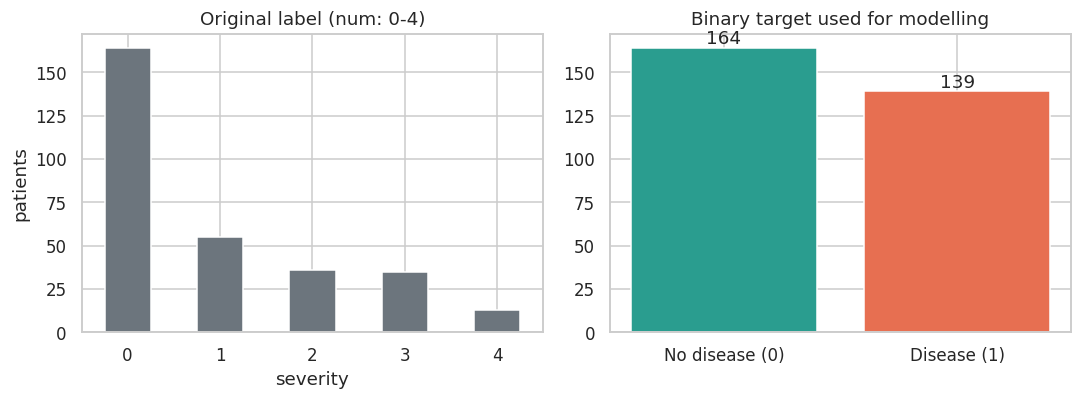

{0: 0.541, 1: 0.459}


In [4]:
df = clean(raw)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
raw["num"].value_counts().sort_index().plot.bar(ax=axes[0], color="#6c757d", rot=0)
axes[0].set_title("Original label (num: 0-4)")
axes[0].set_xlabel("severity"); axes[0].set_ylabel("patients")
counts = df[config.TARGET].value_counts().sort_index()
bars = axes[1].bar(["No disease (0)", "Disease (1)"], counts.values, color=["#2a9d8f", "#e76f51"])
axes[1].bar_label(bars)
axes[1].set_title("Binary target used for modelling")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "eda_class_balance.png", dpi=150)
plt.show()
print((counts / counts.sum()).round(3).to_dict())

The binary target is close to balanced (54% / 46%), so accuracy is meaningful and no resampling is needed. I still report recall and ROC-AUC because missing a diseased patient is the costlier error.

## 4. Numeric features

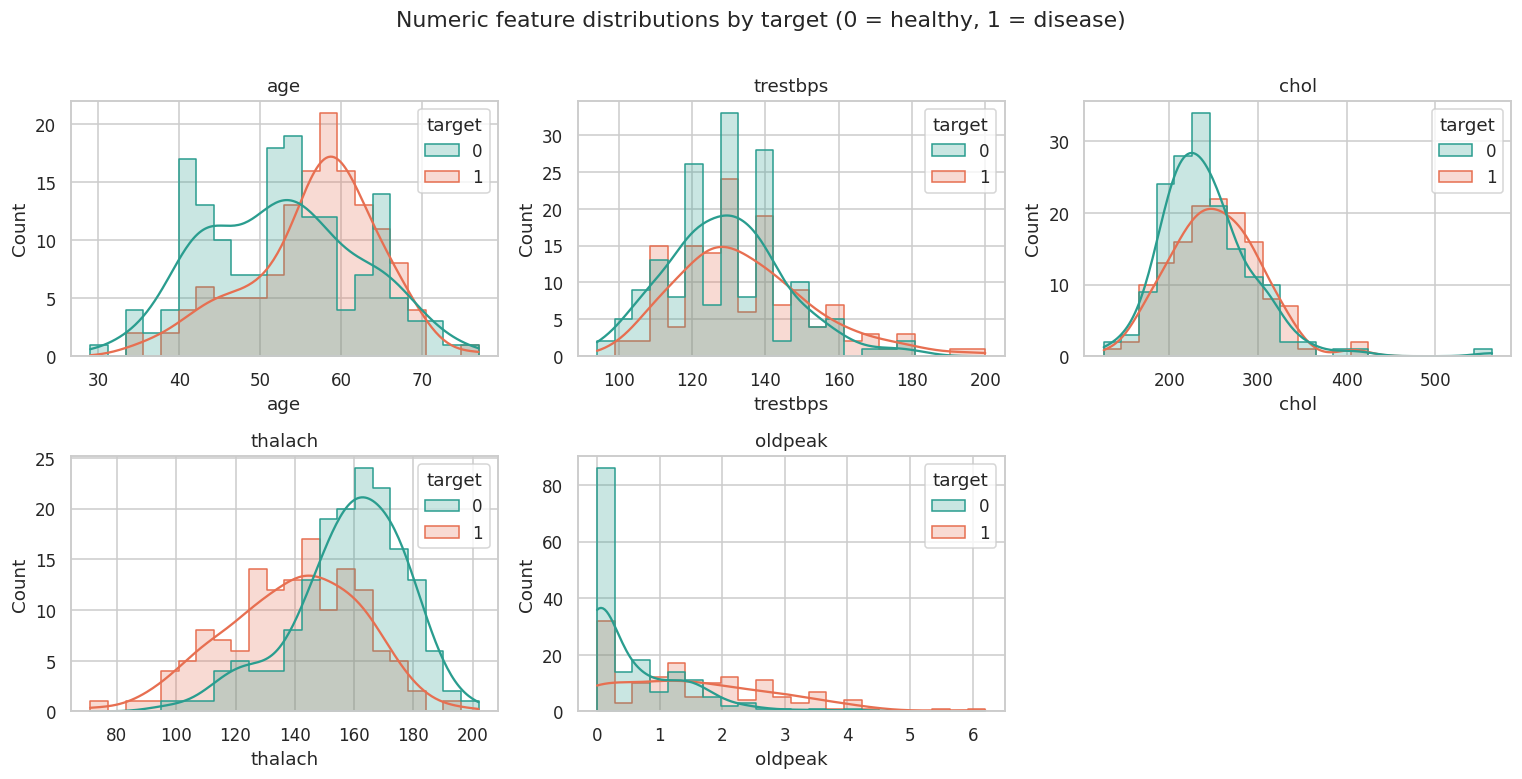

,age,trestbps,chol,thalach,oldpeak
target,,,,,
0,52.59,129.25,242.64,158.38,0.59
1,56.63,134.57,251.47,139.26,1.57


In [5]:
numeric = config.NUMERIC_FEATURES
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), numeric):
    sns.histplot(data=df, x=col, hue=config.TARGET, kde=True, bins=22, ax=ax,
                 palette=["#2a9d8f", "#e76f51"], element="step")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.suptitle("Numeric feature distributions by target (0 = healthy, 1 = disease)", y=1.01)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "eda_histograms.png", dpi=150, bbox_inches="tight")
plt.show()
df.groupby(config.TARGET)[numeric].mean().round(2)

Patients with disease are older on average (56.6 vs 52.6), reach a lower maximum heart rate (139 vs 158) and show a much larger ST depression (`oldpeak` 1.6 vs 0.6). `oldpeak` is right-skewed and `chol` has a few extreme values (max 564), which is why numeric columns are standardised.

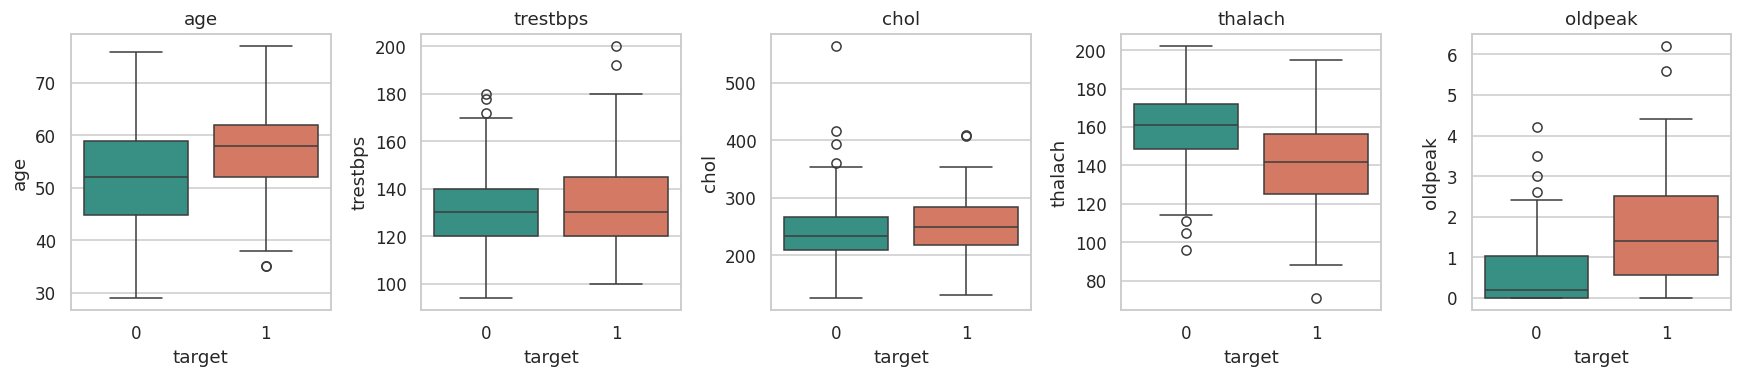

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, col in zip(axes, numeric):
    sns.boxplot(data=df, x=config.TARGET, y=col, ax=ax, palette=["#2a9d8f", "#e76f51"], hue=config.TARGET, legend=False)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "eda_boxplots.png", dpi=150)
plt.show()

## 5. Categorical features

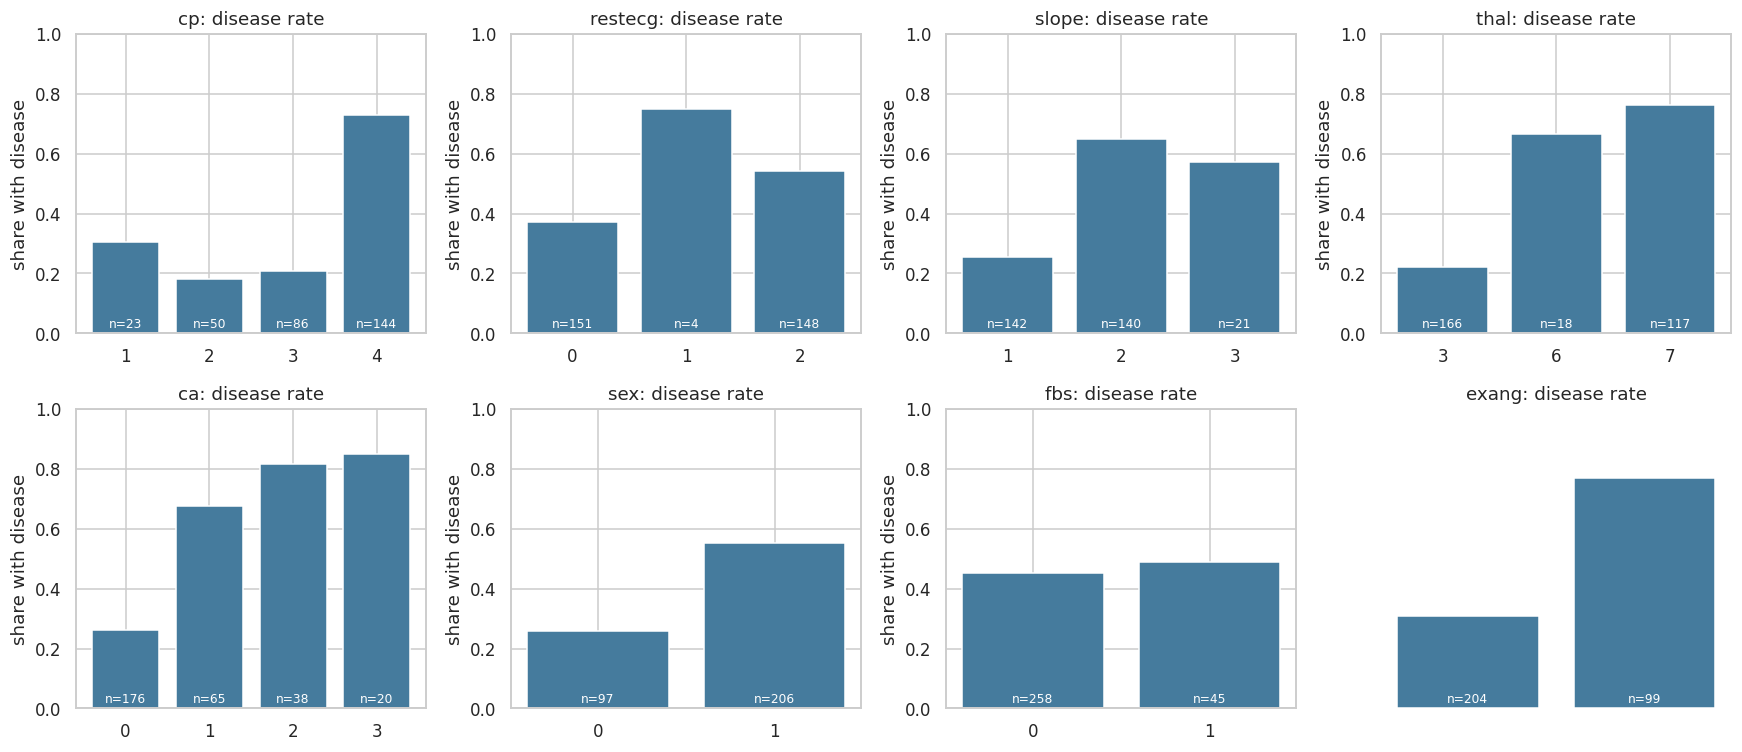

In [7]:
cats = config.CATEGORICAL_FEATURES + config.BINARY_FEATURES
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), cats):
    rate = df.groupby(col)[config.TARGET].agg(["mean", "size"])
    bars = ax.bar(rate.index.astype(int).astype(str), rate["mean"], color="#457b9d")
    ax.set_ylim(0, 1); ax.set_title(f"{col}: disease rate"); ax.set_ylabel("share with disease")
    for b, n in zip(bars, rate["size"]):
        ax.text(b.get_x() + b.get_width() / 2, 0.02, f"n={n}", ha="center", color="white", fontsize=8)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "eda_categorical.png", dpi=150)
plt.show()

Strong separators: asymptomatic chest pain (`cp`=4) has a 73% disease rate versus 18-30% for other types; exercise angina 77% vs 31%; `ca` rises from 26% (0 vessels) to 85% (3 vessels); reversible defect (`thal`=7) 76% vs 22% for normal.

## 6. Correlations

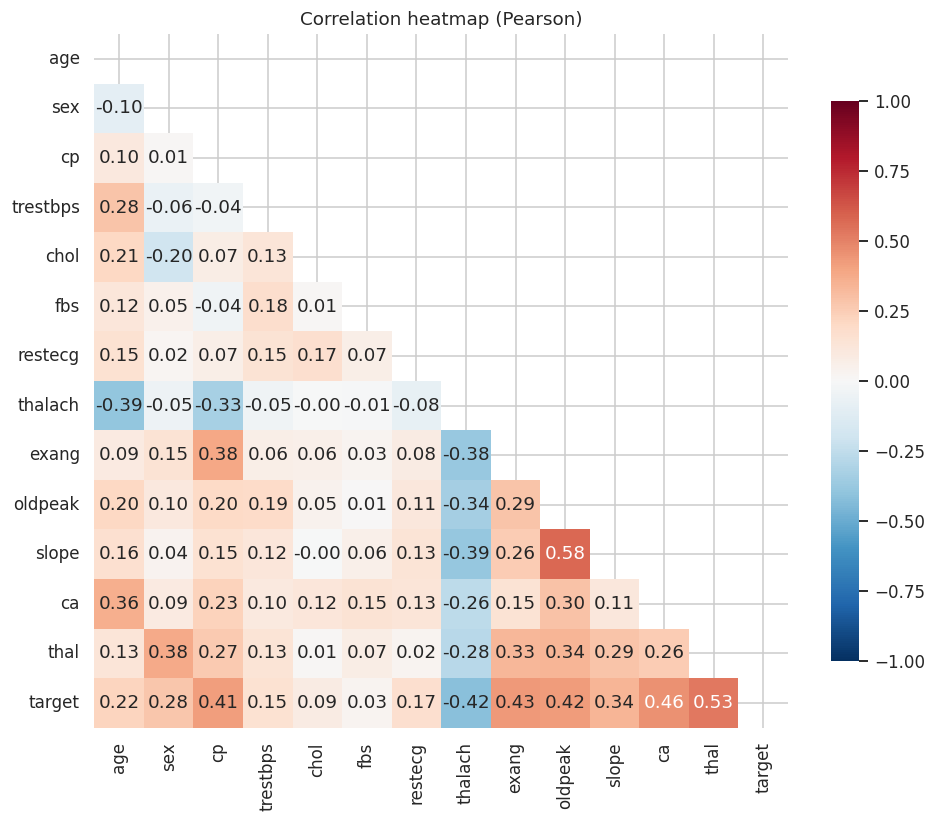

thal        0.526
ca          0.460
exang       0.432
oldpeak     0.425
thalach    -0.417
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
Name: target, dtype: float64

In [8]:
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(9, 7.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation heatmap (Pearson)")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "eda_correlation.png", dpi=150)
plt.show()
corr[config.TARGET].drop(config.TARGET).sort_values(key=abs, ascending=False).round(3)

Most correlated with the target: `thal` (0.53), `ca` (0.46), `exang` (0.43), `oldpeak` (0.43), `thalach` (-0.42), `cp` (0.41). Predictors are only moderately correlated with each other (no pair above |0.6|), so multicollinearity is not a concern for logistic regression. `chol` and `fbs` are almost uncorrelated with the target (0.09 and 0.03) on their own, but they are kept: their interactions are not captured by a linear correlation.

Pearson on ordinal/categorical codes is only a rough guide; the disease-rate bars above are more reliable for those columns.

## 7. Save cleaned dataset

In [9]:
from src.data import prepare_clean_dataset
prepare_clean_dataset()
pd.read_csv(config.CLEAN_PATH).shape

(303, 14)